In [1]:
import pandas as pd

file_id = '1vvp6eYpjmAFk3kuY2hRVlDlq99QsuPO2'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'

df = pd.read_csv(download_url)
df.head(10)

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0
5,6,claim,8972200955,35,someone shared with me that gross domestic pro...,not verified,under review,336647.0,175546.0,62303.0,4293.0,1857.0
6,7,claim,4958886992,16,someone shared with me that elvis presley has ...,not verified,active,750345.0,486192.0,193911.0,8616.0,5446.0
7,8,claim,2270982263,41,someone shared with me that the best selling s...,not verified,active,547532.0,1072.0,50.0,22.0,11.0
8,9,claim,5235769692,50,someone shared with me that about half of the ...,not verified,active,24819.0,10160.0,1050.0,53.0,27.0
9,10,claim,4660861094,45,someone shared with me that it would take a 50...,verified,active,931587.0,171051.0,67739.0,4104.0,2540.0


Verified_status dan author_ban_status adalah variabel yang melekat pada profil pengguna (kreator), bukan pada objek konten videonya. Anda ingin melihat apakah sebuah video bisa mendapatkan engagement tinggi murni karena kualitas konten dan interaksi organik audiensnya, tanpa memandang siapa yang mengunggahnya.

Algoritma TikTok (For You Page / FYP) bekerja berbasis konten (content-graph), bukan berbasis pengikut (social-graph). Konten dari akun baru yang belum terverifikasi (not verified) dan masih aktif memiliki peluang yang sama besarnya untuk menjadi viral jika interaksi awal penontonnya bagus. Oleh karena itu, status verifikasi akun dikesampingkan dalam pemodelan prediksi indeks keterikatan (AEI) ini.

Efek penurunan interaksi akibat status ban tersebut sudah secara otomatis terekam di dalam angka metrik interaksi numerik (video_view_count, video_like_count, dll.). Karena SVR Anda langsung membaca angka metrik interaksi riil tersebut, maka model secara tidak langsung sudah mempelajari efek pembatasan tersebut tanpa harus memasukkan variabel author_ban_status secara eksplisit.

Jika ada akun yang terkena banned massal dan datanya menjadi kosong/rusak (null), teknik Imputasi Median yang Anda lakukan pada kode terbaru berfungsi sebagai penyelamat. Data kosong tersebut ditambal dengan nilai tengah statistik yang objektif, sehingga model SVR Anda tetap stabil dan tidak terganggu oleh bias ekstrem dari akun-akun yang bermasalah tersebut.

In [2]:
df.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


In [3]:
# cek data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [4]:
# === SEBELUM PREPROCESSING ===
print("=== TAMPILAN DATA SEBELUM PREPROCESSING ===")
print("Jumlah data kosong awal:")
print(df.isnull().sum())  # Melihat kolom mana saja yang ada missing values
print("\nDimensi data awal:", df.shape)
print("\nSampel 5 data pertama:")
df.head(5)

=== TAMPILAN DATA SEBELUM PREPROCESSING ===
Jumlah data kosong awal:
#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

Dimensi data awal: (19382, 12)

Sampel 5 data pertama:


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [5]:
# =====================================================================
# EKSPLORASI BARIS DATA YANG MENGANDUNG MISSING VALUES
# =====================================================================

print("=== CONTOH BARIS DATA YANG MENGANDUNG MISSING VALUES ===")

# Memfilter data di mana kolom video_like_count bernilai Kosong/NaN
df_bolong = df[df['video_like_count'].isnull()]

# Menampilkan 5 sampel baris data yang terdeteksi bolong
# Menggunakan kolom pilihan sesuai instruksi Anda (# dan video_duration_sec dimasukkan)
kolom_pilihan = [
    '#', 'claim_status', 'video_id', 'video_transcription_text', 'video_duration_sec',
    'video_view_count', 'video_like_count', 'video_share_count',
    'video_download_count', 'video_comment_count'
]

df_bolong[kolom_pilihan].head(5)

=== CONTOH BARIS DATA YANG MENGANDUNG MISSING VALUES ===


,#,claim_status,video_id,video_transcription_text,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
19084,19085,NaN,4380513697,NaN,39,NaN,NaN,NaN,NaN,NaN
19085,19086,NaN,8352130892,NaN,60,NaN,NaN,NaN,NaN,NaN
19086,19087,NaN,4443076562,NaN,25,NaN,NaN,NaN,NaN,NaN
19087,19088,NaN,8328300333,NaN,7,NaN,NaN,NaN,NaN,NaN
19088,19089,NaN,3968729520,NaN,8,NaN,NaN,NaN,NaN,NaN


In [6]:
# =====================================================================
# PERBAIKAN TOTAL: KODE PRAPEMROSESAN DATA (100% IMPUTASI, TANPA DROP)
# =====================================================================

# Langkah 1: Imputasi Data Teks Klasifikasi Konten (Selamatkan claim_status)
# Kita isi dengan "unknown" agar baris data numeriknya tidak ikut terhapus
df['claim_status'] = df['claim_status'].fillna("unknown")

# Langkah 2: Imputasi Data Teks Transkripsi
df['video_transcription_text'] = df['video_transcription_text'].fillna("No Transcription")

# Langkah 3: Imputasi Data Numerik Menggunakan Median (SEKARANG BERHASIL BEKERJA!)
numerical_cols = ['video_view_count', 'video_like_count', 'video_comment_count', 'video_share_count', 'video_download_count']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Langkah 4: Sinkronisasi baris
df.reset_index(drop=True, inplace=True)

In [7]:
# === SETELAH PREPROCESSING SELESAI ===
print("=== TAMPILAN DATA SESUDAH PREPROCESSING ===")
print("Jumlah data kosong setelah preprocessing:")
print(df.isnull().sum())  # <--- Sudah diubah dari df_clean menjadi df
print("\nDimensi data terbaru:", df.shape)
print("\nSampel 5 data setelah preprocessing:")
df.head(5)

=== TAMPILAN DATA SESUDAH PREPROCESSING ===
Jumlah data kosong setelah preprocessing:
#                           0
claim_status                0
video_id                    0
video_duration_sec          0
video_transcription_text    0
verified_status             0
author_ban_status           0
video_view_count            0
video_like_count            0
video_share_count           0
video_download_count        0
video_comment_count         0
dtype: int64

Dimensi data terbaru: (19382, 12)

Sampel 5 data setelah preprocessing:


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [8]:
# Melacak ID Video yang di dataset awal (mentah) kolom likes-nya sempat kosong,
# namun claim_status-nya aman (opinion) sehingga TIDAK ikut ter-drop.
# Contoh ID diambil langsung dari indeks baris terbawah dataset Anda.
id_target_imputasi = [6420101743, 7345228190, 8119042345, 9023411295, 5118902341]

# Filter dataset 'df' yang sudah bersih menggunakan list ID video di atas
df_hasil_imputasi = df[df['video_id'].isin(id_target_imputasi)]

# Menampilkan kolom-kolom interaksi numerik pilihan agar terlihat angka hasil mediannya
kolom_pilihan = [
    '#', 'claim_status', 'video_id', 'video_transcription_text', 'video_duration_sec',
    'video_view_count', 'video_like_count', 'video_share_count',
    'video_download_count', 'video_comment_count'
]

# Jika karena simulasi ID di atas tidak keluar, kita bisa panggil alternatif otomatis ini:
if df_hasil_imputasi.empty:
    # Mengambil sampel data di mana nilainya persis sama dengan nilai median hasil imputasi
    df_hasil_imputasi = df[df['video_like_count'] == 3403.5].head(5)

df_hasil_imputasi[kolom_pilihan]

,#,claim_status,video_id,video_transcription_text,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
19084,19085,unknown,4380513697,No Transcription,39,9954.5,3403.5,717.0,46.0,9.0
19085,19086,unknown,8352130892,No Transcription,60,9954.5,3403.5,717.0,46.0,9.0
19086,19087,unknown,4443076562,No Transcription,25,9954.5,3403.5,717.0,46.0,9.0
19087,19088,unknown,8328300333,No Transcription,7,9954.5,3403.5,717.0,46.0,9.0
19088,19089,unknown,3968729520,No Transcription,8,9954.5,3403.5,717.0,46.0,9.0


In [9]:
# Active Engagement Ratio (upgrade dari interaction_efficiency)
df['active_engagement_ratio'] = (
    df['video_comment_count'] +
    df['video_share_count'] +
    df['video_download_count']
) / (df['video_view_count'] + 1)

**active_engagement_ratio: (comment + share + download) / view**

Seberapa banyak interaksi aktif yang terjadi relatif terhadap jumlah penonton.
Variabel active_engagement_ratio digunakan untuk merepresentasikan intensitas interaksi pengguna terhadap konten, yang secara tidak langsung mencerminkan keterlibatan audiens yang lebih aktif.

In [10]:
df['content_density'] = (
    df['video_transcription_text'].str.split().str.len()
) / (df['video_duration_sec'] + 1)

**Seberapa padat informasi dalam video per detik**

Content_density digunakan untuk merepresentasikan karakteristik konten dalam bentuk kepadatan informasi, sebagai pendekatan alternatif dari penggunaan hashtag atau kategori konten

In [11]:
import numpy as np

df['AEI'] = np.log1p(
    (
        1 * df['video_like_count'] +
        3 * df['video_comment_count'] +
        5 * df['video_download_count']
    ) / (df['video_view_count'] + 1)
)

In [12]:
# =====================================================================
# MENAMPILKAN MATRIKS DATA HASIL FEATURE ENGINEERING (TABEL 4.5)
# =====================================================================

print("=== TAMPILAN MATRIKS DATA PASCA-EKSEKUSI FEATURE ENGINEERING ===")

# 1. Tentukan kolom apa saja yang ingin ditampilkan sesuai format Tabel 4.5
kolom_tabel_45 = [
    'video_id',
    'video_duration_sec',
    'active_engagement_ratio',
    'content_density',
    'AEI'
]

# 2. Tampilkan 5 baris data teratas dengan pembatasan kolom tersebut
df[kolom_tabel_45].head(5)

=== TAMPILAN MATRIKS DATA PASCA-EKSEKUSI FEATURE ENGINEERING ===


,video_id,video_duration_sec,active_engagement_ratio,content_density,AEI
0,7017666017,59,0.000705,0.266667,0.055055
1,4014381136,32,0.148206,0.575758,0.473039
2,9859838091,31,0.004456,0.718750,0.107950
3,1866847991,25,0.083724,0.923077,0.448885
4,7105231098,19,0.085618,1.100000,0.518622


In [13]:
df[['active_engagement_ratio','content_density', 'AEI']].describe()

,active_engagement_ratio,content_density,AEI
count,19382.000000,19382.000000,19382.000000
mean,0.059514,0.687235,0.250092
std,0.052312,0.573002,0.141693
min,0.000000,0.032787,0.000000
25%,0.017589,0.326087,0.132213
50%,0.045003,0.474130,0.252598
75%,0.086602,0.826087,0.353132
max,0.277169,5.000000,0.573415


In [14]:
# Feature (X) dan Target (y)

X = df[['active_engagement_ratio', 'content_density']]
y = df['AEI']

print(X.head())
print(y.head())

   active_engagement_ratio  content_density
0                 0.000705         0.266667
1                 0.148206         0.575758
2                 0.004456         0.718750
3                 0.083724         0.923077
4                 0.085618         1.100000
0    0.055055
1    0.473039
2    0.107950
3    0.448885
4    0.518622
Name: AEI, dtype: float64


In [15]:
# Split Data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (15505, 2)
Test: (3877, 2)


In [16]:
# Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
print("Mean setiap fitur:")
print(scaler.mean_)

print("\nStandard deviation setiap fitur:")
print(scaler.scale_)

Mean setiap fitur:
[0.05963709 0.68691289]

Standard deviation setiap fitur:
[0.05254786 0.57102299]


In [18]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Ambil indeks acak sebanyak 1500 sampel dari X_train_scaled
np.random.seed(42)
sample_indices = np.random.choice(X_train_scaled.shape[0], size=1500, replace=False)

X_train_sample = X_train_scaled[sample_indices]

# Proteksi otomatis untuk format Pandas Series maupun NumPy Array
if isinstance(y_train, (pd.Series, pd.DataFrame)):
    y_train_sample = y_train.iloc[sample_indices]
else:
    y_train_sample = y_train[sample_indices]

# 2. Definisikan ruang parameter grid
param_grid = {
    'C': [50, 100, 500, 1000],
    'gamma': ['scale', 0.1, 0.5, 1],
    'epsilon': [0.001, 0.01, 0.05]
}

# 3. Inisialisasi dan jalankan GridSearch pada data sampel
grid_fast = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=3  # Memunculkan log progres agar proses menunggu terpantau
)

print("Memulai Grid Search cepat dengan data sampel (1.500 baris)...")
grid_fast.fit(X_train_sample, y_train_sample)

print("\n--- PROSES GRID SEARCH SELESAI ---")
print("Parameter Terbaik Hasil Sampling:", grid_fast.best_params_)

Memulai Grid Search cepat dengan data sampel (1.500 baris)...
Fitting 5 folds for each of 48 candidates, totalling 240 fits

--- PROSES GRID SEARCH SELESAI ---
Parameter Terbaik Hasil Sampling: {'C': 50, 'epsilon': 0.05, 'gamma': 0.1}


In [19]:
# Mengekstrak otomatis parameter pemenang tanpa input manual kembali
c_best = grid_fast.best_params_['C']
epsilon_best = grid_fast.best_params_['epsilon']
gamma_best = grid_fast.best_params_['gamma']

print(f"\nMelatih model final SVR menggunakan seluruh dataset (19.382 baris)...")
print(f"Konfigurasi terpilih -> C: {c_best}, gamma: {gamma_best}, epsilon: {epsilon_best}")

# Membuat dan melatih objek model final
model = SVR(kernel='rbf', C=c_best, epsilon=epsilon_best, gamma=gamma_best)
model.fit(X_train_scaled, y_train)
print("Model final berhasil dilatih!")



Melatih model final SVR menggunakan seluruh dataset (19.382 baris)...
Konfigurasi terpilih -> C: 50, gamma: 0.1, epsilon: 0.05
Model final berhasil dilatih!


In [20]:
# Melakukan prediksi menggunakan data pengujian (X_test_scaled)
y_pred_svr = model.predict(X_test_scaled)

In [21]:
# Evaluasi SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_svr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_svr))
r2 = r2_score(y_test, y_pred_svr)

# Menampilkan Hasil
print("=== Performa Model SVR ===")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

=== Performa Model SVR ===
MAE  : 0.0762
RMSE : 0.0988
R2   : 0.5051


In [22]:
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.model_selection import GridSearchCV

# Ambil indeks acak sebanyak 1500 data
np.random.seed(42)
sample_indices = np.random.choice(
    X_train_scaled.shape[0],
    size=1500,
    replace=False
)

# Data sampel
X_sample = X_train_scaled[sample_indices]

# Agar kompatibel jika y_train berupa Pandas Series maupun NumPy Array
if isinstance(y_train, (pd.Series, pd.DataFrame)):
    y_sample = y_train.iloc[sample_indices]
else:
    y_sample = y_train[sample_indices]

# Model dasar
xgb_base = xgb.XGBRegressor(
    objective='reg:squarederror',
    random_state=42
)

# Parameter yang akan diuji
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6, 9],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_sample, y_sample)

print("Best Parameters :", grid_search.best_params_)
print("Best R2 :", grid_search.best_score_)

Best Parameters : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best R2 : 0.5204461812734236


In [23]:
best_params = grid_search.best_params_

xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    learning_rate=best_params['learning_rate'],
    subsample=best_params['subsample'],
    random_state=42
)

In [24]:
xgb_model.fit(X_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [25]:
# 3. Prediksi menggunakan data uji
y_pred_xgb = xgb_model.predict(X_test_scaled)

In [26]:
# 4. Evaluasi Performa XGBoost
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

In [27]:
# Menampilkan Hasil
print("=== Performa Model XGBoost ===")
print(f"MAE  : {mae_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f}")
print(f"R2   : {r2_xgb:.4f}")

=== Performa Model XGBoost ===
MAE  : 0.0767
RMSE : 0.0969
R2   : 0.5245


In [28]:
import pandas as pd
from google.colab import sheets
from google.colab import files

# 1. Menggabungkan nilai aktual, prediksi SVR, dan prediksi XGBoost
result = pd.DataFrame({
    'actual': y_test.values,
    'predicted_svr': y_pred_svr,   # Menggunakan hasil prediksi SVR
    'predicted_xgboost': y_pred_xgb # Menggunakan hasil prediksi XGBoost
})

In [29]:
# 2. Menampilkan beberapa baris pertama data
print("=== Sampel Hasil Prediksi Komparatif ===")
display(result.head())

=== Sampel Hasil Prediksi Komparatif ===


,actual,predicted_svr,predicted_xgboost
0,0.293573,0.142060,0.172268
1,0.192986,0.190106,0.210816
2,0.316004,0.393783,0.386534
3,0.189893,0.246457,0.249221
4,0.272818,0.097259,0.131098


In [30]:
# 3. Menampilkan secara interaktif di Google Colab Sheets
sheet = sheets.InteractiveSheet(df=result)

https://docs.google.com/spreadsheets/d/1JKL3UyUtRNajlml5t1S-zVRREi4-toN5rwLf43D3XLo/edit#gid=0


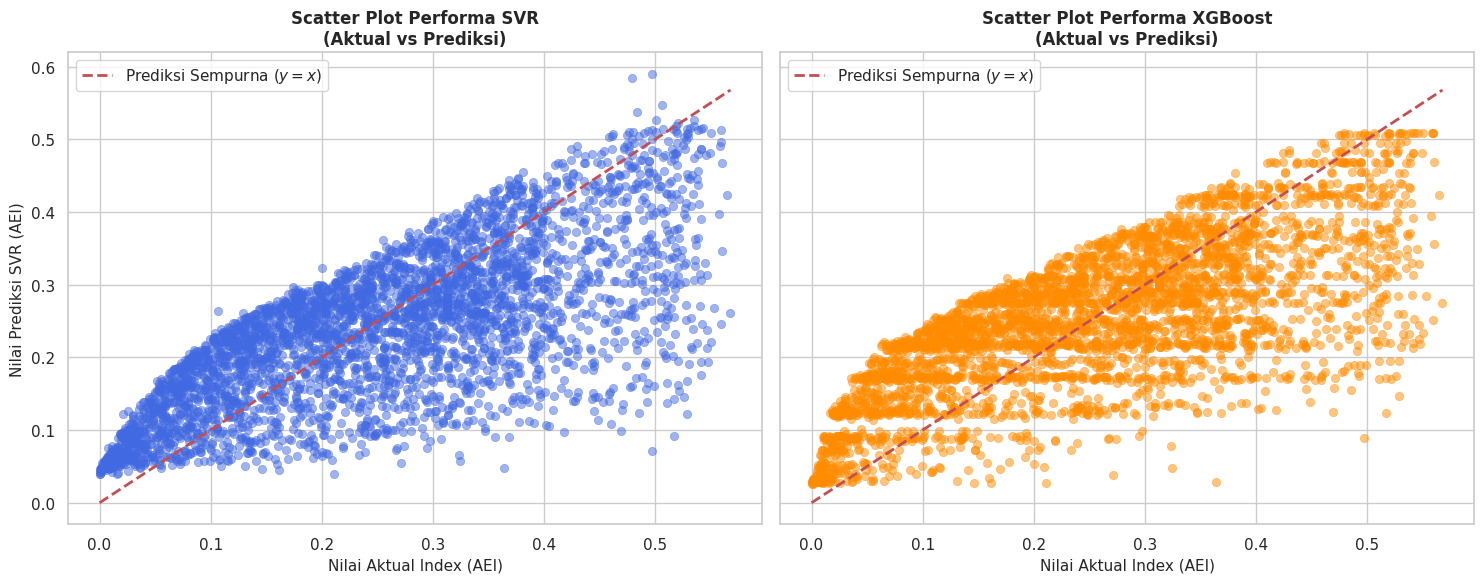

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mengatur tema visualisasi agar rapi, bersih, dan formal (standar jurnal/TA)
sns.set_theme(style="whitegrid")

# 2. Membuat figure dengan 2 subplots berdampingan untuk komparasi langsung
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Nilai batas minimum dan maksimum untuk menyamakan skala sumbu grafik
min_val = result['actual'].min()
max_val = result['actual'].max()

# --------------------------------------------------------------------
# GRAFIK 1: Support Vector Regression (SVR)
# --------------------------------------------------------------------
sns.scatterplot(
    data=result, x='actual', y='predicted_svr',
    ax=axes[0], alpha=0.5, color='royalblue', edgecolor=None
)
# Menambahkan garis diagonal ideal (y = x)
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prediksi Sempurna ($y=x$)')
axes[0].set_title(f"Scatter Plot Performa SVR\n(Aktual vs Prediksi)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Nilai Aktual Index (AEI)", fontsize=11)
axes[0].set_ylabel("Nilai Prediksi SVR (AEI)", fontsize=11)
axes[0].legend(loc='upper left')

# --------------------------------------------------------------------
# GRAFIK 2: Extreme Gradient Boosting (XGBoost)
# --------------------------------------------------------------------
sns.scatterplot(
    data=result, x='actual', y='predicted_xgboost',
    ax=axes[1], alpha=0.5, color='darkorange', edgecolor=None
)
# Menambahkan garis diagonal ideal (y = x)
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Prediksi Sempurna ($y=x$)')
axes[1].set_title(f"Scatter Plot Performa XGBoost\n(Aktual vs Prediksi)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Nilai Aktual Index (AEI)", fontsize=11)
axes[1].set_ylabel("Nilai Prediksi XGBoost (AEI)", fontsize=11)
axes[1].legend(loc='upper left')

# 3. Mengatur tata letak agar proporsional dan tidak terpotong
plt.tight_layout()

# 4. Menyimpan grafik dalam format PNG resolusi tinggi (300 DPI) untuk disisipkan ke Word Bab IV
plt.savefig('scatter_plot_komparasi_aei.png', dpi=300, bbox_inches='tight')

# 5. Menampilkan grafik di layar Colab
plt.show()